In [85]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style='whitegrid')

# Configuração de semente aleatória para reprodutibilidade
np.random.seed(42)

# 1. Criação do conjunto de dados fictício
n_registros = 300

datas = pd.date_range(start="2026-01-01", periods=120, freq="D")
produtos = ["Notebook", "Mouse Gaming", "Teclado Mecânico", "Monitor 4K", "Cadeira Ergonômica"]
categorias = {
    "Notebook": "Eletrônicos",
    "Mouse Gaming": "Acessórios",
    "Teclado Mecânico": "Acessórios",
    "Monitor 4K": "Eletrônicos",
    "Cadeira Ergonômica": "Móveis"
}
precos_base = {
    "Notebook": 4500.00,
    "Mouse Gaming": 150.00,
    "Teclado Mecânico": 350.00,
    "Monitor 4K": 1800.00,
    "Cadeira Ergonômica": 1200.00
}
regioes = ["Sudeste", "Sul", "Nordeste", "Centro-Oeste", "Norte"]

prod_escolhidos = np.random.choice(produtos, size=n_registros)
qtd_escolhidas = np.random.randint(1, 10, size=n_registros)

df = pd.DataFrame({
    "id_transacao": range(1001, 1001 + n_registros),
    "data": np.random.choice(datas, size=n_registros),
    "produto": prod_escolhidos,
    "categoria": [categorias[p] for p in prod_escolhidos],
    "preco_unitario": [precos_base[p] for p in prod_escolhidos],
    "quantidade": qtd_escolhidas,
    "desconto_percentual": np.random.choice([0.0, 0.05, 0.10, 0.15], size=n_registros, p=[0.5, 0.2, 0.2, 0.1]),
    "regiao": np.random.choice(regioes, size=n_registros, p=[0.4, 0.2, 0.2, 0.1, 0.1]),
    "avaliacao_cliente": np.random.choice([1, 2, 3, 4, 5, np.nan], size=n_registros, p=[0.05, 0.05, 0.15, 0.35, 0.35, 0.05])
})

# Calculando faturamento bruto e líquido
df["faturamento_bruto"] = df["preco_unitario"] * df["quantidade"]
df["faturamento_liquido"] = df["faturamento_bruto"] * (1 - df["desconto_percentual"])

# Inserindo alguns valores nulos intencionais para treino de limpeza
df.loc[df.sample(frac=0.03).index, "faturamento_liquido"] = np.nan

In [86]:
print("--- Primeiras 5 linhas do DataFrame ---")
print(df.head())

--- Primeiras 5 linhas do DataFrame ---
   id_transacao       data             produto    categoria  preco_unitario  \
0          1001 2026-03-18          Monitor 4K  Eletrônicos          1800.0   
1          1002 2026-02-02  Cadeira Ergonômica       Móveis          1200.0   
2          1003 2026-04-08    Teclado Mecânico   Acessórios           350.0   
3          1004 2026-04-15  Cadeira Ergonômica       Móveis          1200.0   
4          1005 2026-04-09  Cadeira Ergonômica       Móveis          1200.0   

   quantidade  desconto_percentual    regiao  avaliacao_cliente  \
0           5                 0.15  Nordeste                4.0   
1           8                 0.05       Sul                4.0   
2           1                 0.05  Nordeste                2.0   
3           5                 0.00       Sul                4.0   
4           3                 0.10   Sudeste                1.0   

   faturamento_bruto  faturamento_liquido  
0             9000.0               765

In [87]:
df.head()
df.tail()

,id_transacao,data,produto,categoria,preco_unitario,quantidade,desconto_percentual,regiao,avaliacao_cliente,faturamento_bruto,faturamento_liquido
295,1296,2026-04-04,Cadeira Ergonômica,Móveis,1200.0,1,0.05,Sul,4.0,1200.0,1140.0
296,1297,2026-04-30,Cadeira Ergonômica,Móveis,1200.0,5,0.00,Nordeste,3.0,6000.0,6000.0
297,1298,2026-04-12,Teclado Mecânico,Acessórios,350.0,9,0.10,Nordeste,4.0,3150.0,2835.0
298,1299,2026-02-20,Monitor 4K,Eletrônicos,1800.0,6,0.00,Sul,4.0,10800.0,10800.0
299,1300,2026-03-03,Notebook,Eletrônicos,4500.0,1,0.00,Sudeste,4.0,4500.0,4500.0


In [88]:
#df.info()
#df.describe()
df.columns.tolist()

['id_transacao',
 'data',
 'produto',
 'categoria',
 'preco_unitario',
 'quantidade',
 'desconto_percentual',
 'regiao',
 'avaliacao_cliente',
 'faturamento_bruto',
 'faturamento_liquido']

In [90]:
p = df['faturamento_bruto']
subset = df[['produto', 'avaliacao_cliente']]
print(subset)

                produto  avaliacao_cliente
0            Monitor 4K                4.0
1    Cadeira Ergonômica                4.0
2      Teclado Mecânico                2.0
3    Cadeira Ergonômica                4.0
4    Cadeira Ergonômica                1.0
..                  ...                ...
295  Cadeira Ergonômica                4.0
296  Cadeira Ergonômica                3.0
297    Teclado Mecânico                4.0
298          Monitor 4K                4.0
299            Notebook                4.0

[300 rows x 2 columns]


In [91]:
valor = df.loc[0, 'produto']
print(valor)

valor = df.iloc[0, 2]
print(valor)


Monitor 4K
Monitor 4K


In [92]:
estoque = df[(df['quantidade'] > 5) & (df['regiao'] == 'Sul')]
print(estoque.shape)

(21, 11)


In [93]:
df.isnull().sum()

,0
id_transacao,0
data,0
produto,0
categoria,0
preco_unitario,0
quantidade,0
desconto_percentual,0
regiao,0
avaliacao_cliente,16
faturamento_bruto,0


In [94]:
mediana = df['faturamento_liquido'].median

df['faturamento_liquido'].fillna(mediana, inplace=True)

/tmp/ipykernel_6334/481092115.py:3: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '<bound method Series.median of 0       7650.0
1       9120.0
2        332.5
3       6000.0
4       3240.0
        ...   
295     1140.0
296     6000.0
297     2835.0
298    10800.0
299     4500.0
Name: faturamento_liquido, Length: 300, dtype: float64>' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df['faturamento_liquido'].fillna(mediana, inplace=True)


In [95]:
d = df.duplicated()

In [96]:
sorted = df.sort_values(
    by = 'produto',
    ascending=True
)

print(sorted)
print(df['quantidade'].sum())

     id_transacao       data             produto   categoria  preco_unitario  \
47           1048 2026-02-23  Cadeira Ergonômica      Móveis          1200.0   
37           1038 2026-04-23  Cadeira Ergonômica      Móveis          1200.0   
206          1207 2026-04-09  Cadeira Ergonômica      Móveis          1200.0   
198          1199 2026-04-21  Cadeira Ergonômica      Móveis          1200.0   
191          1192 2026-01-26  Cadeira Ergonômica      Móveis          1200.0   
..            ...        ...                 ...         ...             ...   
30           1031 2026-01-01    Teclado Mecânico  Acessórios           350.0   
89           1090 2026-01-30    Teclado Mecânico  Acessórios           350.0   
189          1190 2026-01-02    Teclado Mecânico  Acessórios           350.0   
245          1246 2026-02-10    Teclado Mecânico  Acessórios           350.0   
181          1182 2026-02-25    Teclado Mecânico  Acessórios           350.0   

     quantidade  desconto_percentual   

In [97]:
df.groupby('regiao')['faturamento_bruto'].mean()

,faturamento_bruto
regiao,
Centro-Oeste,9827.142857
Nordeste,10151.408451
Norte,6563.235294
Sudeste,8905.454545
Sul,6448.000000


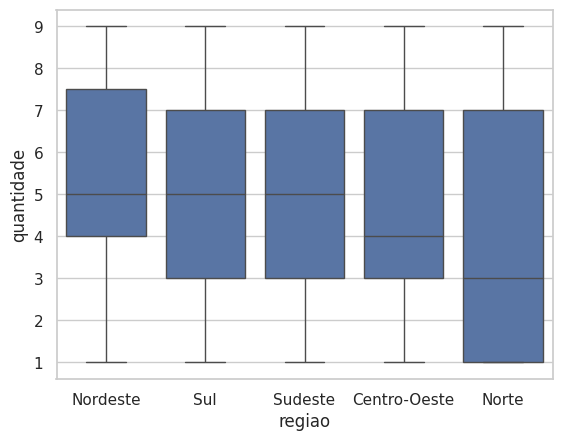

In [107]:
sns.boxplot(
    data=df,
    x='regiao',
    y='quantidade'
)
plt.show()

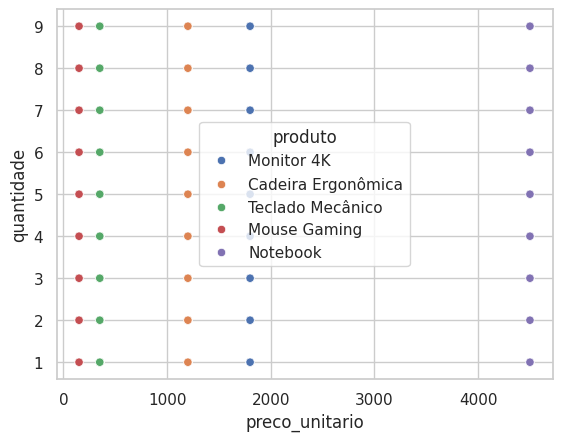

In [106]:
# Dispersão com correlação
sns.scatterplot(
    data=df,
    x='preco_unitario',
    y='quantidade',
    hue='produto'
)
plt.show()

